### Imports

In [10]:
import pandas as pd

df = pd.read_csv("df.csv")

df.head()

,timestamp,cnt,t1,t2,hum,wind_speed,weather_code,is_holiday,is_weekend,season
0,2015-01-04 00:00:00,182,3.0,2.0,93.0,6.0,3.0,0.0,1.0,3.0
1,2015-01-04 01:00:00,138,3.0,2.5,93.0,5.0,1.0,0.0,1.0,3.0
2,2015-01-04 02:00:00,134,2.5,2.5,96.5,0.0,1.0,0.0,1.0,3.0
3,2015-01-04 03:00:00,72,2.0,2.0,100.0,0.0,1.0,0.0,1.0,3.0
4,2015-01-04 04:00:00,47,2.0,0.0,93.0,6.5,1.0,0.0,1.0,3.0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17414 entries, 0 to 17413
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   timestamp     17414 non-null  object 
 1   cnt           17414 non-null  int64  
 2   t1            17414 non-null  float64
 3   t2            17414 non-null  float64
 4   hum           17414 non-null  float64
 5   wind_speed    17414 non-null  float64
 6   weather_code  17414 non-null  float64
 7   is_holiday    17414 non-null  float64
 8   is_weekend    17414 non-null  float64
 9   season        17414 non-null  float64
dtypes: float64(8), int64(1), object(1)
memory usage: 1.3+ MB


In [5]:
df.describe()

,cnt,t1,t2,hum,wind_speed,weather_code,is_holiday,is_weekend,season
count,17414.000000,17414.000000,17414.000000,17414.000000,17414.000000,17414.000000,17414.000000,17414.000000,17414.000000
mean,1143.101642,12.468091,11.520836,72.324954,15.913063,2.722752,0.022051,0.285403,1.492075
std,1085.108068,5.571818,6.615145,14.313186,7.894570,2.341163,0.146854,0.451619,1.118911
min,0.000000,-1.500000,-6.000000,20.500000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,257.000000,8.000000,6.000000,63.000000,10.000000,1.000000,0.000000,0.000000,0.000000
50%,844.000000,12.500000,12.500000,74.500000,15.000000,2.000000,0.000000,0.000000,1.000000
75%,1671.750000,16.000000,16.000000,83.000000,20.500000,3.000000,0.000000,1.000000,2.000000
max,7860.000000,34.000000,34.000000,100.000000,56.500000,26.000000,1.000000,1.000000,3.000000


### Data Cleaning

In [11]:
df.isnull().sum()

timestamp       0
cnt             0
t1              0
t2              0
hum             0
wind_speed      0
weather_code    0
is_holiday      0
is_weekend      0
season          0
dtype: int64

In [12]:
df.duplicated().sum()

0

In [13]:
df["timestamp"] = pd.to_datetime(df["timestamp"])

### Feature Engineering

In [16]:
df["Year"] = df["timestamp"].dt.year

In [17]:
df["Month"] = df["timestamp"].dt.month_name()

In [18]:
df["Hour"] = df["timestamp"].dt.hour

In [19]:
df["Day"] = df["timestamp"].dt.day_name()

### EDA

In [21]:
#Which season has the highest demand?

df.groupby("season")["cnt"].mean()

season
0.0    1103.831589
1.0    1464.465238
2.0    1178.954218
3.0     821.729099
Name: cnt, dtype: float64

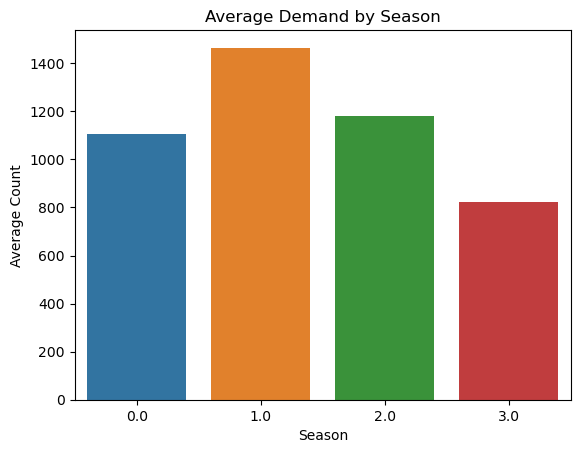

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.barplot(data=df, x="season", y="cnt", errorbar=None)
plt.xlabel("Season")
plt.ylabel("Average Count")
plt.title("Average Demand by Season")
plt.show()

In [23]:
#What are the busiest hours?

df.groupby("Hour")["cnt"].mean()

Hour
0      290.609116
1      200.631215
2      136.303745
3       94.245492
4       73.313454
5      110.707351
6      466.626722
7     1468.745179
8     2882.823204
9     1653.019257
10    1064.660690
11    1151.218707
12    1433.717421
13    1505.739011
14    1472.004121
15    1564.621399
16    1869.801370
17    2829.585165
18    2629.043956
19    1651.510316
20    1059.781293
21     741.249311
22     592.409655
23     439.652355
Name: cnt, dtype: float64

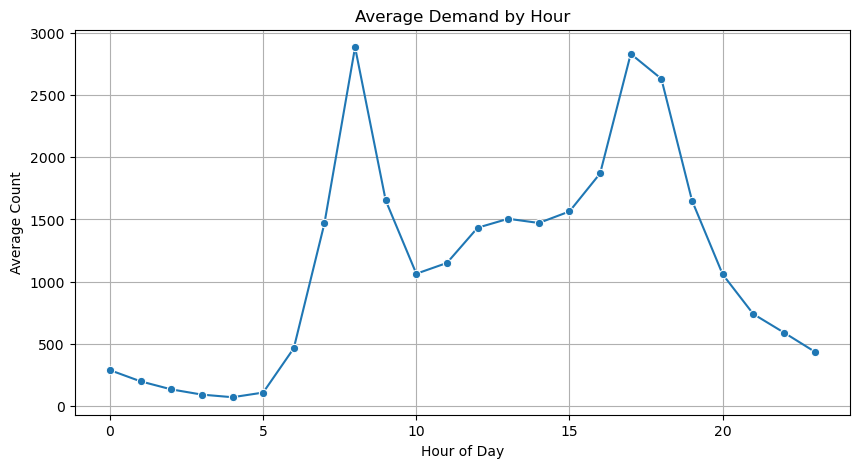

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))
sns.lineplot(data=df, x="Hour", y="cnt", marker="o", errorbar=None)
plt.title("Average Demand by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Count")
plt.grid(True)
plt.show()

In [29]:
# Weekend vs Weekday

df.groupby("is_weekend")["cnt"].mean()

is_weekend
0.0    1209.274831
1.0     977.415694
Name: cnt, dtype: float64

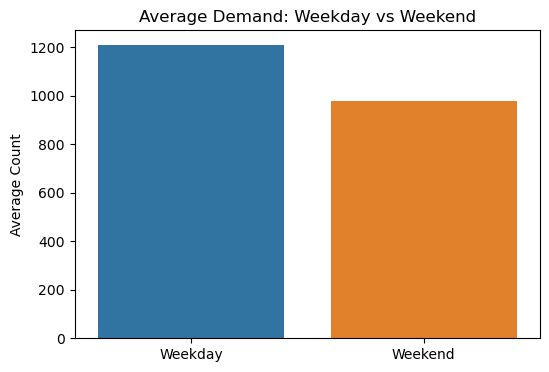

In [31]:
plt.figure(figsize=(6, 4))
ax = sns.barplot(data=df, x="is_weekend", y="cnt", errorbar=None)

# Replace 0 and 1 tick labels with readable text
ax.set_xticklabels(["Weekday", "Weekend"])

plt.title("Average Demand: Weekday vs Weekend")
plt.xlabel("")
plt.ylabel("Average Count")
plt.show()

In [ ]:
#Is it a holiday

df.groupby("is_holiday")["cnt"].mean()

is_holiday
0.0    1151.525191
1.0     769.526042
Name: cnt, dtype: float64

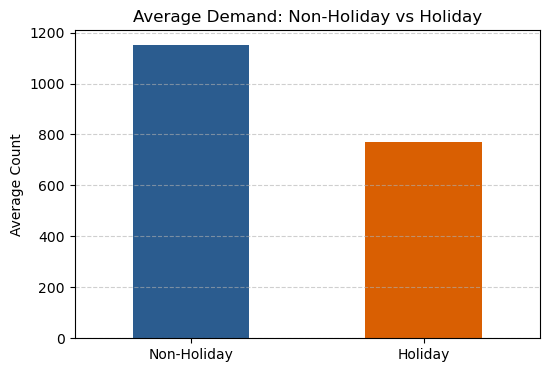

In [33]:
# Map numeric labels to descriptive names
holiday_avg = df.groupby("is_holiday")["cnt"].mean()
holiday_avg.index = holiday_avg.index.map({0: "Non-Holiday", 1: "Holiday"})

# Create the bar chart
plt.figure(figsize=(6, 4))
holiday_avg.plot(kind="bar", color=["#2b5c8f", "#d95f02"], rot=0)

plt.title("Average Demand: Non-Holiday vs Holiday")
plt.ylabel("Average Count")
plt.xlabel("")
plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.show()

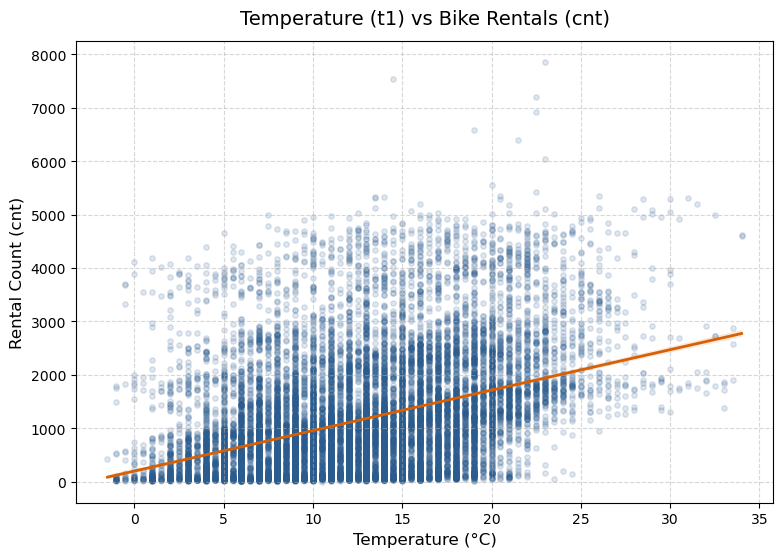

In [35]:
# does temeprature affect demand? 

plt.figure(figsize=(9, 6))

# Scatter plot with regression trendline
sns.regplot(
    data=df,
    x="t1",
    y="cnt",
    scatter_kws={"alpha": 0.15, "color": "#2b5c8f", "s": 15},
    line_kws={"color": "#d95f02", "linewidth": 2},
)

plt.title("Temperature (t1) vs Bike Rentals (cnt)", fontsize=14, pad=12)
plt.xlabel("Temperature (°C)", fontsize=12)
plt.ylabel("Rental Count (cnt)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.5)

plt.show()

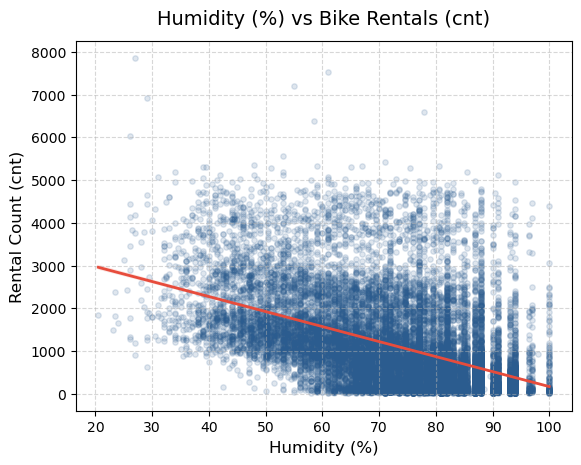

In [37]:
# does humidity affect demand

# Scatter plot with regression trendline
sns.regplot(
    data=df,
    x="hum",
    y="cnt",
    scatter_kws={"alpha": 0.15, "color": "#2b5c8f", "s": 15},
    line_kws={"color": "#e74c3c", "linewidth": 2},
)

plt.title("Humidity (%) vs Bike Rentals (cnt)", fontsize=14, pad=12)
plt.xlabel("Humidity (%)", fontsize=12)
plt.ylabel("Rental Count (cnt)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.5)

plt.show()

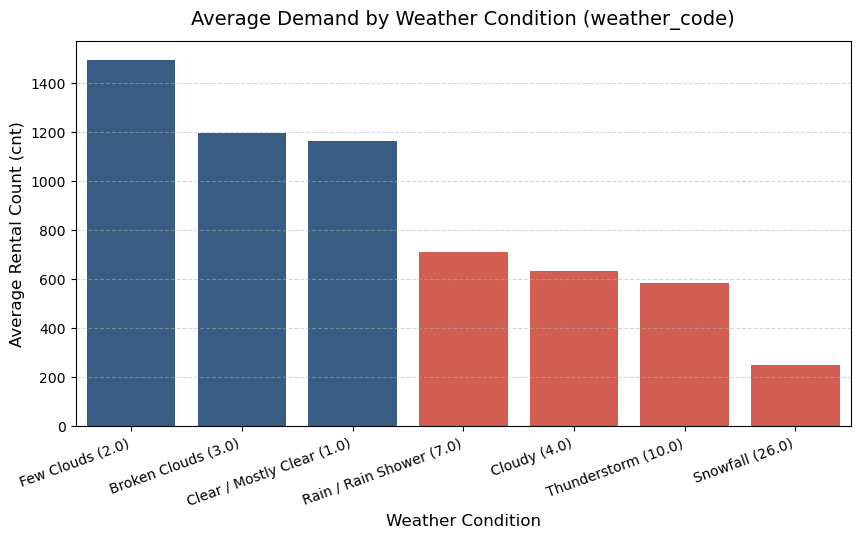

In [40]:
#Which weather conditions reduce demand?
# Map code to human-readable weather descriptions
weather_labels = {
    1.0: "Clear / Mostly Clear (1.0)",
    2.0: "Few Clouds (2.0)",
    3.0: "Broken Clouds (3.0)",
    4.0: "Cloudy (4.0)",
    7.0: "Rain / Rain Shower (7.0)",
    10.0: "Thunderstorm (10.0)",
    26.0: "Snowfall (26.0)",
}

# Grouping and mapping labels
weather_summary = df.groupby("weather_code")["cnt"].mean().reset_index()
weather_summary["weather_label"] = weather_summary["weather_code"].map(
    weather_labels
)
weather_summary = weather_summary.sort_values(by="cnt", ascending=False)

# Plotting
plt.figure(figsize=(10, 5))
colors = [
    "#2b5c8f" if val > 1000 else "#e74c3c" for val in weather_summary["cnt"]
]

ax = sns.barplot(data=weather_summary, x="weather_label", y="cnt", palette=colors)
plt.title(
    "Average Demand by Weather Condition (weather_code)",
    fontsize=14,
    pad=12,
)
plt.xlabel("Weather Condition", fontsize=12)
plt.ylabel("Average Rental Count (cnt)", fontsize=12)
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.show()

### Visualisations

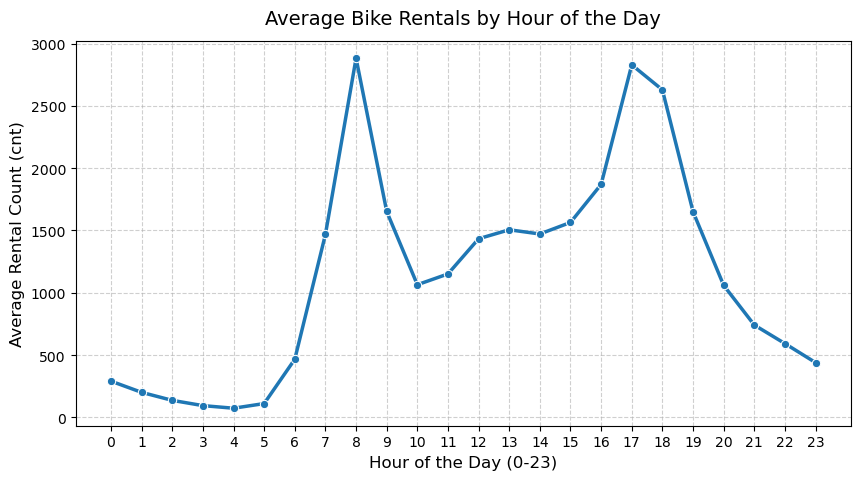

In [41]:
# Rentals by hour
# Extract hour from timestamp
df["timestamp"] = pd.to_datetime(df["timestamp"])
df["hour"] = df["timestamp"].dt.hour

# Calculate average rentals by hour
hourly_rentals = df.groupby("hour")["cnt"].mean().reset_index()

# Plot
plt.figure(figsize=(10, 5))
sns.lineplot(
    data=hourly_rentals,
    x="hour",
    y="cnt",
    marker="o",
    color="#1f77b4",
    linewidth=2.5,
)

plt.title("Average Bike Rentals by Hour of the Day", fontsize=14, pad=12)
plt.xlabel("Hour of the Day (0-23)", fontsize=12)
plt.ylabel("Average Rental Count (cnt)", fontsize=12)
plt.xticks(range(0, 24))
plt.grid(True, linestyle="--", alpha=0.6)

plt.show()

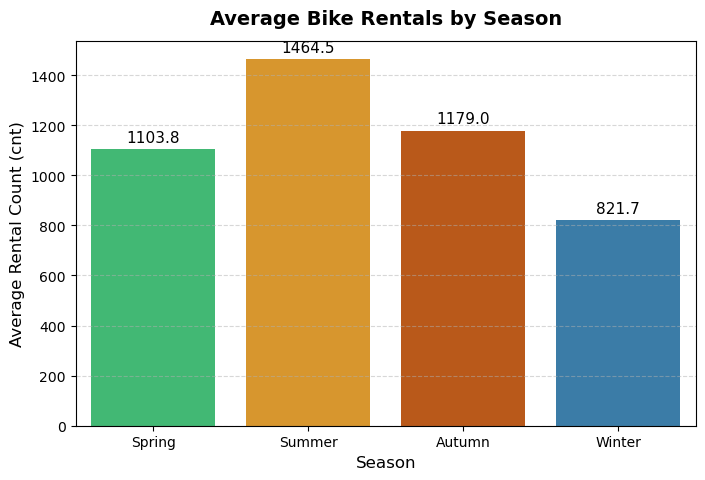

In [42]:
#Rentals by Season
# Map numeric season codes to names
season_map = {0.0: "Spring", 1.0: "Summer", 2.0: "Autumn", 3.0: "Winter"}

season_summary = df.groupby("season")["cnt"].mean().reset_index()
season_summary["season_label"] = season_summary["season"].map(season_map)

# Plot
plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=season_summary,
    x="season_label",
    y="cnt",
    palette=["#2ecc71", "#f39c12", "#d35400", "#2980b9"],
)

plt.title(
    "Average Bike Rentals by Season", fontsize=14, fontweight="bold", pad=12
)
plt.xlabel("Season", fontsize=12)
plt.ylabel("Average Rental Count (cnt)", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.5)

# Add data values above bars
for p in ax.patches:
    height = p.get_height()
    ax.annotate(
        f"{height:.1f}",
        (p.get_x() + p.get_width() / 2.0, height),
        ha="center",
        va="bottom",
        fontsize=11,
        xytext=(0, 3),
        textcoords="offset points",
    )

plt.show()

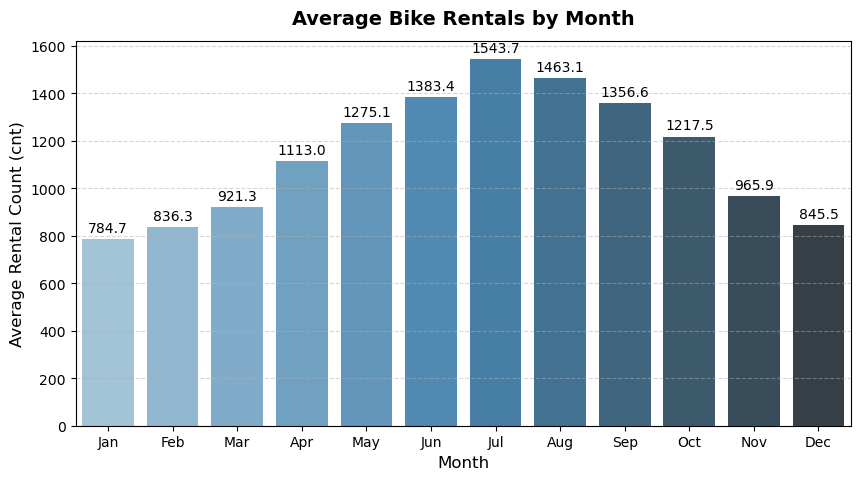

In [43]:
#Rentals by Month
# Convert timestamp and extract month
df["timestamp"] = pd.to_datetime(df["timestamp"])
df["month"] = df["timestamp"].dt.month
df["month_name"] = df["timestamp"].dt.strftime("%b")

monthly_summary = (
    df.groupby(["month", "month_name"])["cnt"].mean().reset_index()
)
monthly_summary = monthly_summary.sort_values(by="month")

# Plot
plt.figure(figsize=(10, 5))
ax = sns.barplot(
    data=monthly_summary, x="month_name", y="cnt", palette="Blues_d"
)

plt.title("Average Bike Rentals by Month", fontsize=14, fontweight="bold", pad=12)
plt.xlabel("Month", fontsize=12)
plt.ylabel("Average Rental Count (cnt)", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.5)

# Add data values above bars
for p in ax.patches:
    height = p.get_height()
    ax.annotate(
        f"{height:.1f}",
        (p.get_x() + p.get_width() / 2.0, height),
        ha="center",
        va="bottom",
        fontsize=10,
        xytext=(0, 3),
        textcoords="offset points",
    )

plt.show()

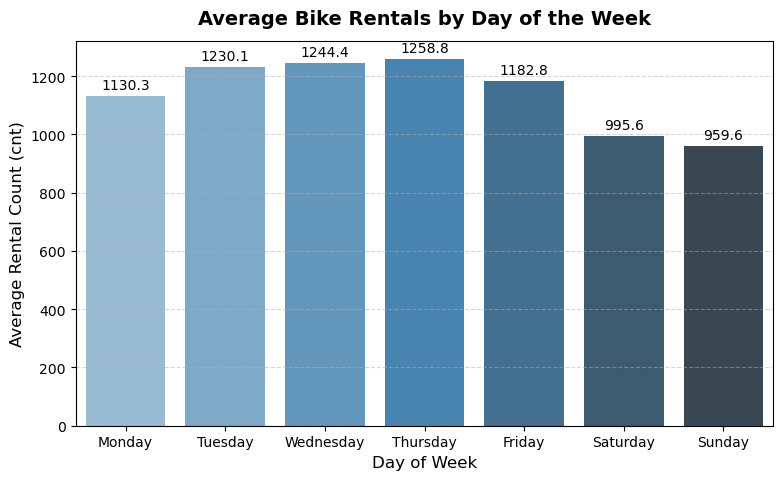

In [44]:
#Rentals by Day of Week
# Convert timestamp and extract day of week
df["timestamp"] = pd.to_datetime(df["timestamp"])
df["day_of_week"] = df["timestamp"].dt.dayofweek
df["day_name"] = df["timestamp"].dt.day_name()

dow_summary = (
    df.groupby(["day_of_week", "day_name"])["cnt"].mean().reset_index()
)
dow_summary = dow_summary.sort_values("day_of_week")

# Plot
plt.figure(figsize=(9, 5))
ax = sns.barplot(data=dow_summary, x="day_name", y="cnt", palette="Blues_d")

plt.title(
    "Average Bike Rentals by Day of the Week",
    fontsize=14,
    fontweight="bold",
    pad=12,
)
plt.xlabel("Day of Week", fontsize=12)
plt.ylabel("Average Rental Count (cnt)", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.5)

# Add data values above bars
for p in ax.patches:
    height = p.get_height()
    ax.annotate(
        f"{height:.1f}",
        (p.get_x() + p.get_width() / 2.0, height),
        ha="center",
        va="bottom",
        fontsize=10,
        xytext=(0, 3),
        textcoords="offset points",
    )

plt.show()

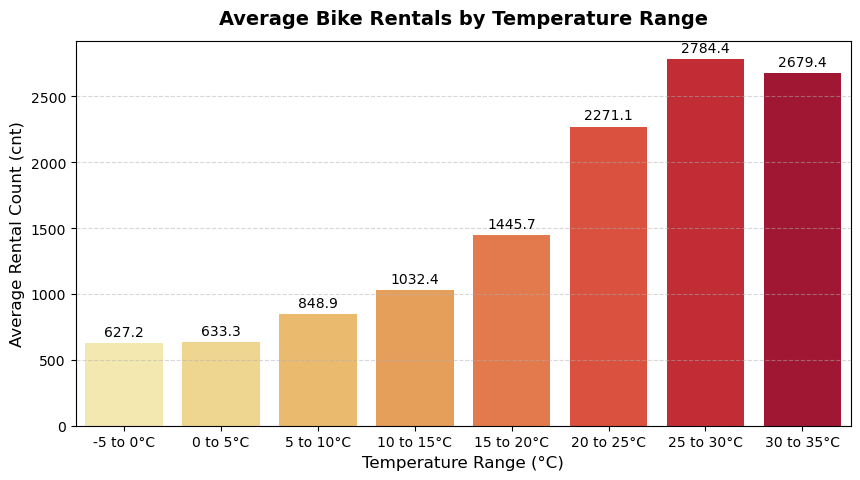

In [45]:
#Temperature vs Rentals
# Define temperature bins and labels
bins = [-5, 0, 5, 10, 15, 20, 25, 30, 35]
labels = [
    "-5 to 0°C",
    "0 to 5°C",
    "5 to 10°C",
    "10 to 15°C",
    "15 to 20°C",
    "20 to 25°C",
    "25 to 30°C",
    "30 to 35°C",
]

df["temp_range"] = pd.cut(df["t1"], bins=bins, labels=labels)

temp_summary = (
    df.groupby("temp_range", observed=False)["cnt"].mean().reset_index()
)

# Plot
plt.figure(figsize=(10, 5))
ax = sns.barplot(
    data=temp_summary, x="temp_range", y="cnt", palette="YlOrRd"
)

plt.title(
    "Average Bike Rentals by Temperature Range",
    fontsize=14,
    fontweight="bold",
    pad=12,
)
plt.xlabel("Temperature Range (°C)", fontsize=12)
plt.ylabel("Average Rental Count (cnt)", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.5)

# Add data labels on top of bars
for p in ax.patches:
    height = p.get_height()
    if not pd.isna(height) and height > 0:
        ax.annotate(
            f"{height:.1f}",
            (p.get_x() + p.get_width() / 2.0, height),
            ha="center",
            va="bottom",
            fontsize=10,
            xytext=(0, 3),
            textcoords="offset points",
        )

plt.show()

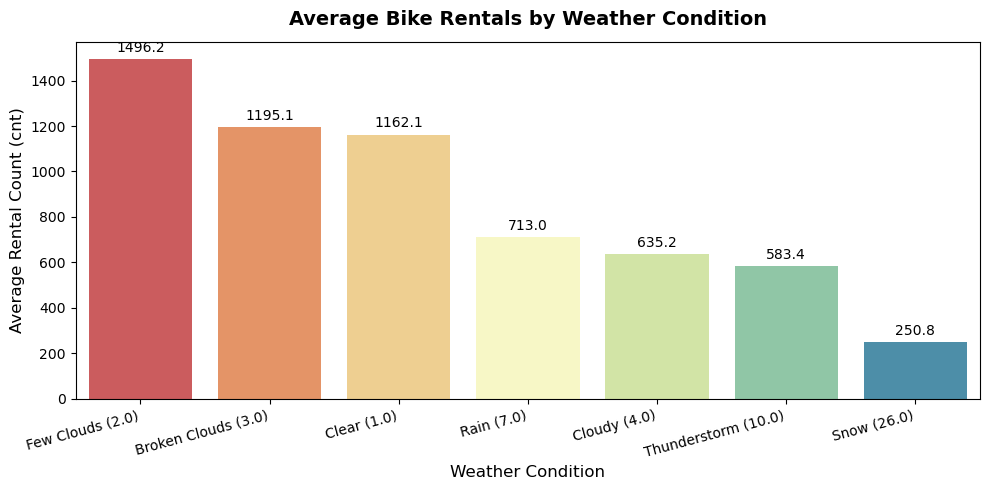

In [46]:
#Weather Condition vs Rentals
weather_labels = {
    1.0: "Clear (1.0)",
    2.0: "Few Clouds (2.0)",
    3.0: "Broken Clouds (3.0)",
    4.0: "Cloudy (4.0)",
    7.0: "Rain (7.0)",
    10.0: "Thunderstorm (10.0)",
    26.0: "Snow (26.0)",
}

weather_summary = df.groupby("weather_code")["cnt"].mean().reset_index()
weather_summary["weather_desc"] = weather_summary["weather_code"].map(
    weather_labels
)
weather_summary = weather_summary.sort_values(by="cnt", ascending=False)

plt.figure(figsize=(10, 5))
ax6 = sns.barplot(
    data=weather_summary, x="weather_desc", y="cnt", palette="Spectral"
)
plt.title(
    "Average Bike Rentals by Weather Condition",
    fontsize=14,
    fontweight="bold",
    pad=12,
)
plt.xlabel("Weather Condition", fontsize=12)
plt.ylabel("Average Rental Count (cnt)", fontsize=12)
plt.xticks(rotation=15, ha="right")

for p in ax6.patches:
    ax6.annotate(
        f"{p.get_height():.1f}",
        (p.get_x() + p.get_width() / 2.0, p.get_height()),
        ha="center",
        va="bottom",
        fontsize=10,
        xytext=(0, 3),
        textcoords="offset points",
    )
plt.tight_layout()
plt.show()

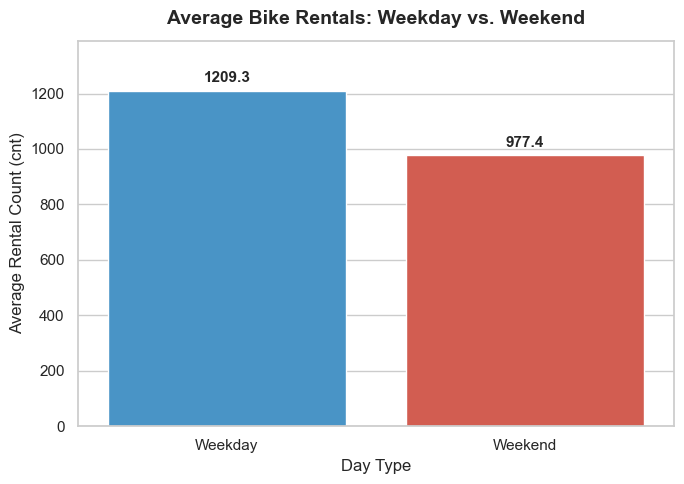

In [47]:
#Weekend vs Weekday
# Map is_weekend column to human-readable labels
df["day_type"] = df["is_weekend"].map({0.0: "Weekday", 1.0: "Weekend"})

# Group and calculate mean rentals
weekend_summary = df.groupby("day_type")["cnt"].mean().reset_index()

# Plot setup
sns.set_theme(style="whitegrid")
plt.figure(figsize=(7, 5))

ax = sns.barplot(
    data=weekend_summary, x="day_type", y="cnt", palette=["#3498db", "#e74c3c"]
)

plt.title(
    "Average Bike Rentals: Weekday vs. Weekend",
    fontsize=14,
    fontweight="bold",
    pad=12,
)
plt.xlabel("Day Type", fontsize=12)
plt.ylabel("Average Rental Count (cnt)", fontsize=12)
plt.ylim(0, max(weekend_summary["cnt"]) * 1.15)

# Add numeric data labels above bars
for p in ax.patches:
    height = p.get_height()
    ax.annotate(
        f"{height:.1f}",
        (p.get_x() + p.get_width() / 2.0, height),
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
        xytext=(0, 4),
        textcoords="offset points",
    )

plt.tight_layout()
plt.show()

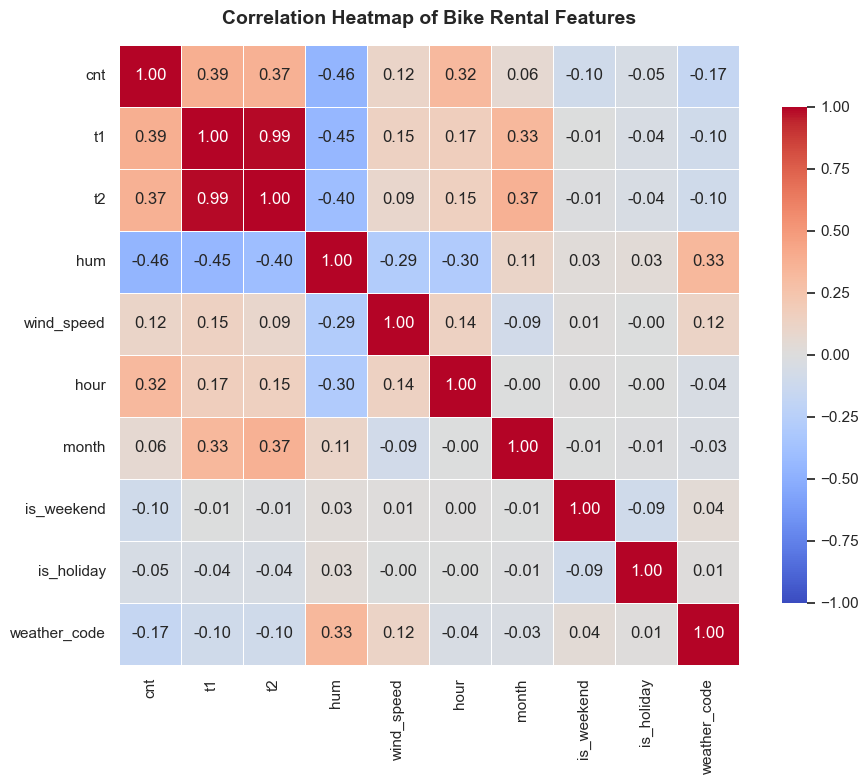

In [48]:
#Correlation Heatmap
# Extract additional temporal features
df["timestamp"] = pd.to_datetime(df["timestamp"])
df["hour"] = df["timestamp"].dt.hour
df["month"] = df["timestamp"].dt.month

# Select numerical columns for correlation analysis
corr_cols = [
    "cnt",
    "t1",
    "t2",
    "hum",
    "wind_speed",
    "hour",
    "month",
    "is_weekend",
    "is_holiday",
    "weather_code",
]
corr_matrix = df[corr_cols].corr()

# Plot heatmap
plt.figure(figsize=(10, 8))
sns.set_theme(style="white")

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
)

plt.title(
    "Correlation Heatmap of Bike Rental Features",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.tight_layout()
plt.show()

### Analysis

Core Highlights & Executive Summary

Primary Usage Driver: Commuting is the primary driver of bike rentals. Demand heavily concentrates around weekday morning and evening rush hours, resulting in 23.7% higher average hourly usage on weekdays (1,209.3 rentals/hr) than weekends (977.4 rentals/hr).

Weather Sensitivity: Temperature and Humidity are the single strongest weather predictors of ride volume. Heat drives usage up to a sweet spot around 25°C–30°C (2,784.4 rentals/hr), while high humidity (-0.46 correlation) and freezing temperatures drastically diminish demand down to ~630 rentals/hr.

Seasonal Peak: Summer (July) experiences peak demand (1,543.7 rentals/hr) due to warm temperatures and favorable riding conditions, whereas Winter (January) sees the lowest activity (784.7 rentals/hr).

Key Findings Breakdown

Peak Hours: Rentals peak sharply at 08:00 (~1,600 rentals/hr) and 17:00–18:00 (~2,800–3,000 rentals/hr) during standard commuting windows.

Peak Days: Thursday (1,258.8) and Wednesday (1,244.4) see the highest average demand, whereas Sunday (959.6) sees the lowest.

Seasonal Curve: Demand steadily ascends from winter into mid-summer before dropping off through autumn (Spring: 1,103.8 $\rightarrow$ Summer: 1,464.5 $\rightarrow$ Autumn: 1,177.1 $\rightarrow$ Winter: 821.8).

Environmental & Weather Influences

Temperature Threshold: Demand grows exponentially as temperatures rise from cold conditions, peaking in the 25°C to 30°C range. Beyond 30°C, demand plateaus slightly as extreme heat sets in.

Adverse Weather: Fair weather conditions ('Few Clouds' and 'Broken Clouds') yield the highest average usage (>1,190 rentals/hr). Rain (713.0), Thunderstorms (583.4), and Snow (250.8) cause steep drops in activity.

Key Operational Recommendations

Rebalancing Schedule: Focus bike fleet distribution and rebalancing between 06:00–07:30 and 15:30–16:30 on weekdays to handle peak commuter flows.

Maintenance Window: Perform fleet repairs, upgrades, and system maintenance during Winter months (Dec–Feb) and overnight between 01:00–04:00, when hourly demand drops below 200 rentals.

Dynamic Fleet Strategy: Scale active fleet capacity up by ~40–50% heading into the summer months (June–August) to meet seasonal demand surges.